## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.cuda.device_count())

1


In [26]:
USE_AMP = torch.cuda.is_available()

In [3]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF2")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [4]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [5]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import numpy as np
import torch

# ---------------- Hugging Face dataset ----------------
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_TEXT_FILES = ["Phase_2_LNER/Train/fold1-text.json", "Phase_2_LNER/Train/fold2-text.json"]
TRAIN_GOLD_FILES = ["Phase_2_LNER/Train/fold1-gold.json", "Phase_2_LNER/Train/fold2-gold.json"]
LABELS_FILE = "Phase_2_LNER/Train/labels.txt"
TEST_TEXT_FILE = "Phase_2_LNER/Test/fold3-text.json"

# ---------------- Phase 1 backbone ----------------
PHASE1_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/prefix-lm"
MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12
N_KV_HEAD = 4

# ---------------- NER data / windowing ----------------
WINDOW_SIZE = 1024        
WINDOW_STRIDE = 512      

# ---------------- Training (Full Fine-Tuning) ----------------
EPOCHS = 15
BATCH_SIZE = 8
GRAD_ACCUM = 2
LR_BACKBONE = 3e-5      # Lower LR for the pretrained backbone
LR_HEAD = 1e-3          # Higher LR for the new classification head
WEIGHT_DECAY = 0.05
WARMUP_RATIO = 0.10
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- Kaggle output ----------------
EXPERIMENT_NAME = "prefixlm_fft_bidir"
OUTPUT_DIR = f"/kaggle/working/cs781_phase2/{EXPERIMENT_NAME}"
MODEL_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")  # Renamed from ADAPTER_PATH
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration loaded:", EXPERIMENT_NAME)

Configuration loaded: prefixlm_fft_bidir


In [6]:
!pip -q install peft regex
from huggingface_hub import hf_hub_download, HfApi

In [7]:
info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_2" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e6:.2f} MB")

Phase_2_LNER/Test/fold3-text.json                                      1.19 MB
Phase_2_LNER/Train/fold1-gold.json                                     0.46 MB
Phase_2_LNER/Train/fold1-text.json                                     1.11 MB
Phase_2_LNER/Train/fold2-gold.json                                     0.48 MB
Phase_2_LNER/Train/fold2-text.json                                     1.12 MB
Phase_2_LNER/Train/labels.txt                                          0.00 MB


## 4. Load Tokenizer

In [8]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style), no external tokenizer libs.

Differences from the plain-bytes version:
  * Text is first split into "words" with a GPT-2 style regex, and merges never
    cross word boundaries. Training and encoding then work on *unique words*
    (with counts) instead of the whole corpus, which is orders of magnitude faster.
  * Training uses incremental pair counts + a lazy max-heap (no full rescan per merge).
  * Encoding applies merges per word by rank, with a word -> ids cache.
  * One special token, <|endoftext|>, used as EOS / PAD / BOS.

Interface:
    tok.encode(text, add_eos=False) -> list[int]
    tok.decode(ids, skip_special_tokens=True) -> str
    tok.vocab_size / tok.get_vocab_size()
    tok.eos_token_id, tok.pad_token_id, tok.bos_token_id
    tok.save(path) / ByteLevelBPE.load(path)
"""

from __future__ import annotations

import heapq
import json
import time
from collections import Counter, defaultdict

import regex as re  # `pip install regex` (needed for \p{L} / \p{N})

# GPT-2 pre-tokenization pattern
_PAT = re.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

EOS_TOKEN = "<|endoftext|>"


class ByteLevelBPE:
    def __init__(self):
        # ids 0-255 = raw bytes; 256.. = learned merges; last id = <|endoftext|>
        self.merges: dict[tuple[int, int], int] = {}      # (a, b) -> new_id (id order == rank order)
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    # alias attributes so the tokenizer plugs into HF-style code
    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id

    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def train(self, text: str, vocab_size: int, verbose: bool = False) -> None:
        """Learn (vocab_size - 257) merges; the final id is reserved for <|endoftext|>."""
        if vocab_size < 257:
            raise ValueError("vocab_size must be at least 257 (256 bytes + EOS)")
        num_merges = vocab_size - 257
        t0 = time.time()

        # 1) pre-tokenize and count unique words
        word_counts = Counter(_PAT.findall(text))
        words = [list(w.encode("utf-8")) for w in word_counts]
        freqs = list(word_counts.values())
        if verbose:
            print(f"[bpe] {len(words):,} unique words from {sum(freqs):,} total words")

        # 2) initial pair statistics
        stats: dict[tuple[int, int], int] = defaultdict(int)
        where: dict[tuple[int, int], set] = defaultdict(set)
        for wi, w in enumerate(words):
            f = freqs[wi]
            for p in zip(w, w[1:]):
                stats[p] += f
                where[p].add(wi)

        # lazy max-heap: (-count, a, b) -> highest count first, ties -> smallest (a, b)
        heap = [(-c, a, b) for (a, b), c in stats.items()]
        heapq.heapify(heap)

        self.merges, self.itos = {}, {i: bytes([i]) for i in range(256)}

        # 3) merge loop
        for i in range(num_merges):
            pair, count = None, 0
            while heap:
                negc, a, b = heapq.heappop(heap)
                if stats.get((a, b), 0) == -negc:   # skip stale heap entries
                    pair, count = (a, b), -negc
                    break
            if pair is None or count < 2:
                break

            new_id = 256 + i
            self.merges[pair] = new_id
            self.itos[new_id] = self.itos[pair[0]] + self.itos[pair[1]]

            touched = set()
            for wi in list(where[pair]):
                w, f = words[wi], freqs[wi]
                # remove this word's old pair contributions
                for p in zip(w, w[1:]):
                    stats[p] -= f
                    where[p].discard(wi)
                    touched.add(p)
                # apply merge (leftmost, non-overlapping)
                a, b = pair
                out, j, n = [], 0, len(w)
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2
                    else:
                        out.append(w[j]); j += 1
                words[wi] = out
                # add new pair contributions
                for p in zip(out, out[1:]):
                    stats[p] += f
                    where[p].add(wi)
                    touched.add(p)

            for p in touched:
                c = stats.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p[0], p[1]))
                else:
                    stats.pop(p, None)
                    where.pop(p, None)

            if verbose and (i % 1000 == 0 or i == num_merges - 1):
                print(f"[bpe] merge {i + 1}/{num_merges} | pair={pair} count={count:,} "
                      f"| elapsed={time.time() - t0:.1f}s")

        self.eos_token_id = 256 + len(self.merges)
        self.vocab_size = self.eos_token_id + 1
        self._cache = {}

    # Inference
    def _encode_word(self, word: str) -> tuple:
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = list(word.encode("utf-8"))
        merges = self.merges
        while len(ids) > 1:
            # pick the applicable merge learned earliest (lowest id)
            best, best_id = None, None
            for p in zip(ids, ids[1:]):
                nid = merges.get(p)
                if nid is not None and (best_id is None or nid < best_id):
                    best, best_id = p, nid
            if best is None:
                break
            a, b = best
            out, j, n = [], 0, len(ids)
            while j < n:
                if j < n - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(best_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        res = tuple(ids)
        if len(self._cache) > 2_000_000:
            self._cache.clear()
        self._cache[word] = res
        return res

    def encode(self, text: str, add_eos: bool = False) -> list[int]:
        ids: list[int] = []
        for w in _PAT.findall(text):
            ids.extend(self._encode_word(w))
        if add_eos:
            ids.append(self.eos_token_id)
        return ids

    def decode(self, ids, skip_special_tokens: bool = True) -> str:
        if hasattr(ids, "tolist"):
            ids = ids.tolist()
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if not skip_special_tokens:
                    parts.append(EOS_TOKEN.encode("utf-8"))
                continue
            parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path: str) -> None:
        data = {
            "merges": [[a, b, nid] for (a, b), nid in self.merges.items()],
            "vocab_size": self.vocab_size,
            "eos_token_id": self.eos_token_id,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    @classmethod
    def load(cls, path: str) -> "ByteLevelBPE":
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        for a, b, nid in data["merges"]:
            tok.merges[(a, b)] = nid
            tok.itos[nid] = tok.itos[a] + tok.itos[b]
        tok.eos_token_id = data["eos_token_id"]
        tok.vocab_size = data["vocab_size"]
        return tok


def train_tokenizer(train_text: str, vocab_size: int):
    """Train a byte-level BPE tokenizer on `train_text` and return it."""
    tok = ByteLevelBPE()
    tok.train(train_text, vocab_size, verbose=True)
    return tok

Overwriting a1_tokenizer.py


In [9]:
from a1_tokenizer import ByteLevelBPE, _PAT

tokenizer = ByteLevelBPE.load(os.path.join(PHASE1_CKPT_DIR, "bpe_tokenizer.json"))
print("Vocabulary size:", len(tokenizer))

Vocabulary size: 32000


In [10]:
def encode_with_offsets(tok, text):
    """Returns ids, starts, ends, is_ws. Offsets are character offsets into `text`,
    end-exclusive, with leading/trailing whitespace trimmed from each token's span.
    is_ws[i] is True for tokens that are whitespace only (no usable span)."""
    ids, starts, ends, is_ws = [], [], [], []
    pos = 0
    for m in _PAT.finditer(text):
        assert m.start() == pos, "pre-tokenizer left a gap in the text"
        pos = m.end()
        word, c0 = m.group(), m.start()
        # byte index within the word -> character index in the text
        b2c = []
        for i, ch in enumerate(word):
            b2c.extend([c0 + i] * len(ch.encode("utf-8")))
        b = 0
        for tid in tok._encode_word(word):
            n = len(tok.itos[tid])
            s, e = b2c[b], b2c[b + n - 1] + 1
            b += n
            while s < e and text[s].isspace(): s += 1
            while e > s and text[e - 1].isspace(): e -= 1
            ids.append(tid); starts.append(s); ends.append(e); is_ws.append(s >= e)
    assert pos == len(text), "pre-tokenizer did not cover the whole text"
    return ids, starts, ends, is_ws

In [11]:
from huggingface_hub import hf_hub_download

def hf_json(path):
    p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=path,
                        repo_type="dataset", token=HF_TOKEN)
    with open(p, encoding="utf-8") as f:
        return json.load(f)

train_text, train_gold, doc_fold = {}, {}, {}
for fold_i, (tf, gf) in enumerate(zip(TRAIN_TEXT_FILES, TRAIN_GOLD_FILES), start=1):
    t, g = hf_json(tf), hf_json(gf)
    train_text.update(t); train_gold.update(g)
    for d in t: doc_fold[d] = fold_i

test_text = hf_json(TEST_TEXT_FILE)

p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=LABELS_FILE,
                    repo_type="dataset", token=HF_TOKEN)
LABELS = [l.strip() for l in open(p, encoding="utf-8") if l.strip()]

print("train docs:", len(train_text), "| gold docs:", len(train_gold), "| test docs:", len(test_text))
print({f: sum(1 for v in doc_fold.values() if v == f) for f in (1, 2)})

train docs: 70 | gold docs: 70 | test docs: 35
{1: 35, 2: 35}


In [12]:
# offsets must reproduce the same ids as the normal encoder
for d in list(train_text)[:5]:
    ids, s, e, w = encode_with_offsets(tokenizer, train_text[d])
    assert ids == tokenizer.encode(train_text[d]), d
print("ids match encode()")

n_tok = [len(encode_with_offsets(tokenizer, t)[0]) for t in train_text.values()]
print("tokens/doc min/mean/max:", min(n_tok), sum(n_tok)//len(n_tok), max(n_tok))

ids match encode()
tokens/doc min/mean/max: 2139 6618 23839


In [13]:
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = {i: t for t, i in TAG2ID.items()}
IGNORE = -100          
print(len(TAGS), "tags:", TAGS[:5], "...")

25 tags: ['O', 'B-APP', 'I-APP', 'B-RESP', 'I-RESP'] ...


In [14]:
def spans_to_bio(starts, ends, is_ws, gold_spans):
    """One tag id per token. gold_spans: [[start, end, label, (text)], ...]"""
    ents = sorted(gold_spans, key=lambda x: (x[0], x[1]))
    tags = []
    k = 0              # pointer into the sorted entities
    prev_ent = -1      # entity index of the previous non-whitespace token
    for i in range(len(starts)):
        if is_ws[i]:
            tags.append(IGNORE)          # whitespace never breaks an entity
            continue
        # skip entities that end at or before this token starts
        while k < len(ents) and ents[k][1] <= starts[i]:
            k += 1
        if k < len(ents) and ents[k][0] <= starts[i] < ents[k][1]:
            prefix = "I-" if prev_ent == k else "B-"
            tags.append(TAG2ID[prefix + ents[k][2]])
            prev_ent = k
        else:
            tags.append(TAG2ID["O"])
            prev_ent = -1
    return tags


def bio_to_spans(starts, ends, is_ws, tag_ids):
    """List of [start_char, end_char, label] from per-token tag ids."""
    spans, cur = [], None            # cur = [start, end, label]
    for i, t in enumerate(tag_ids):
        if is_ws[i] or t == IGNORE:
            continue
        tag = ID2TAG[int(t)]
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "I" and cur is not None and cur[2] == label:
            cur[1] = ends[i]                         # extend the open entity
        else:                                        # "B-" or a stray "I-"
            if cur: spans.append(cur)
            cur = [starts[i], ends[i], label]
    if cur: spans.append(cur)
    return spans

In [15]:
def span_set(spans):
    return {tuple(x[:3]) for x in spans}

tp = ngold = 0
fails = []
for d, ents in train_gold.items():
    text = train_text[d]
    ids, s, e, w = encode_with_offsets(tokenizer, text)
    tags = spans_to_bio(s, e, w, ents)
    back = bio_to_spans(s, e, w, tags)
    g, b = span_set(ents), span_set(back)
    tp += len(g & b); ngold += len(g)
    for x in ents:
        if tuple(x[:3]) not in b:
            fails.append((d, x[0], x[1], x[2], text[max(0, x[0]-10):x[1]+10]))

print(f"round-trip recovery: {tp}/{ngold} = {tp/ngold:.4f}")
for f in fails[:15]:
    print(f)

round-trip recovery: 8242/8393 = 0.9820
('115651329', 10266, 10299, 'PREC', 'e case of State of M.P. vs. Kashiram & Ors.[1], the s')
('975074', 7995, 8085, 'PREC', '1565] and Gambangi Appalaswamy Naldu and Others v. Behara Venkataramanayya Patro [AIR 1984- SC 1728]. Even oth')
('736324', 1963, 1976, 'AUTH', ' down the Railway Boards instruct')
('736324', 11218, 11231, 'AUTH', 'tation of Railway Boards decision')
('736324', 12849, 12901, 'PREC', ' cases in Shankarsan Dash Vs. Union of India [1991 (3) SCC 47]. Para 7 o')
('736324', 14121, 14174, 'PREC', 'C 268] or Jatendra Kumar vs. State of Punjab [(1985) 1 SCC 122]. Hence th')
('1243363', 17853, 17865, 'STAT', 'After the Constitutional Amendme')
('1243363', 25083, 25099, 'AUTH', 'uding the State Governments and the ')
('1243363', 25450, 25466, 'AUTH', 'ws of the State Governments and the ')
('373587', 5927, 5979, 'PREC', 'son. (See Hukam Singh v. State of Rajasthan AIR (1977 SC 1063); Eradu an')
('373587', 5981, 6035, 'PREC', 'SC 1063)

## Encode every document once (train and test)

In [16]:
enc = {}   # doc_id -> (ids, starts, ends, is_ws)
for d, t in {**train_text, **test_text}.items():
    enc[d] = encode_with_offsets(tokenizer, t)

tags_by_doc = {d: spans_to_bio(*enc[d][1:], train_gold[d]) for d in train_gold}
print("encoded docs:", len(enc), "| tagged docs:", len(tags_by_doc))

encoded docs: 105 | tagged docs: 70


## Windows

In [17]:
HEADER_TOKENS = 64

def window_starts(n_tokens, size, stride):
    """Token start positions of the windows covering a document of n_tokens."""
    if n_tokens <= size:
        return [0]
    starts = list(range(0, n_tokens - size + 1, stride))
    if starts[-1] + size < n_tokens:
        starts.append(n_tokens - size)
    return starts

def build_windows(doc_ids, size=WINDOW_SIZE, stride=WINDOW_STRIDE, with_labels=True, header_tokens=HEADER_TOKENS):
    items = []
    body_size = size - header_tokens
    for d in doc_ids:
        ids = enc[d][0]
        tags = tags_by_doc.get(d) if with_labels else None
        n = len(ids)
        header_ids = ids[:header_tokens]

        # key fix: compute starts using body_size, not size — this guarantees the
        # union of [ws, ws+body_size) regions fully covers [0, n) with no gap.
        for ws in window_starts(n, body_size, stride):
            if ws == 0:
                input_ids = ids[0:size]          # window 0 needs no header, uses full size as bonus context
                body_start = 0
            else:
                input_ids = header_ids + ids[ws:ws + body_size]
                body_start = header_tokens
            body_len = len(input_ids) - body_start

            item = {"doc": d, "doc_start": ws, "body_start": body_start, "input_ids": input_ids}
            if with_labels:
                prefix = [IGNORE] * body_start
                item["labels"] = prefix + tags[ws:ws + body_len]
            items.append(item)
    return items

fold1_docs = [d for d, f in doc_fold.items() if f == 1]
fold2_docs = [d for d, f in doc_fold.items() if f == 2]

train_items = build_windows(fold1_docs)
val_items   = build_windows(fold2_docs)
print("train windows:", len(train_items), "| val windows:", len(val_items))

for d in fold1_docs[:5]:
    covered = set()
    for it in train_items:
        if it["doc"] == d:
            body_len = len(it["input_ids"]) - it["body_start"]
            covered.update(range(it["doc_start"], it["doc_start"] + body_len))
    assert covered == set(range(len(enc[d][0]))), d
print("window coverage OK")

train windows: 438 | val windows: 442
window coverage OK


## Collator

In [18]:
PAD_ID = tokenizer.eos_token_id

def ner_collator(batch):
    L = WINDOW_SIZE  # pad every window up to the fixed window size, not just the batch max
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    lab = torch.full((len(batch), L), IGNORE, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.bool)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        mask[i, :n] = True
        if "labels" in b:
            lab[i, :n] = torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}

b = ner_collator(train_items[:4])
print({k: v.shape for k, v in b.items()})

{'input_ids': torch.Size([4, 1024]), 'attention_mask': torch.Size([4, 1024]), 'labels': torch.Size([4, 1024])}


In [19]:
import numpy as np
ent_frac = np.mean([any(l not in (0, IGNORE) for l in it["labels"]) for it in train_items])
print(f"windows containing at least one entity: {ent_frac:.2%}")

windows containing at least one entity: 99.32%


## 9. Define The Model

## Prefix Language Model (Prefix-LM)
Motivation. A standard decoder-only Transformer attends causally everywhere, including over the prompt — so during training it never sees the full 512-word prompt at once, only left-to-right. But the task is "generate a continuation consistent with the whole prompt," not pure left-to-right prediction. Prefix-LM (PaLM, UL2) fixes this: the prompt gets bidirectional attention, the generated part stays causal.

Mechanism. One shared Transformer stack, with a modified attention mask:

Prefix tokens (i < prefix_len): attend to any j < prefix_len — full bidirectional, like BERT. Target tokens (i ≥ prefix_len): attend to any j ≤ i — standard causal, which automatically includes the whole prefix.

This is a lower-triangular causal mask with the top-left prefix_len × prefix_len block made fully visible.

Why not a full encoder-decoder. T5/BART use two separate stacks with cross-attention, suited to tasks where output is structurally different from input (translation, summarization). Here the continuation is just more of the same document — a single shared stack is simpler, more parameter-efficient, and a better match to the task.

Training. prefix_len is sampled per example, biased to 65–80% of the 1024-token block — matching the real prompt:continuation ratio (~512 words of ~640 tokens), so training distribution matches test distribution.

Generation. No real added cost: the first forward pass (full prompt) uses the bidirectional mask; every later step (one new token against the KV cache) is inherently causal, so it just reuses the existing causal path unchanged.

Implementation. Built on the same GQA attention module as the efficient-architecture model, with the mask passed in as an explicit parameter — showing the prefix/causal pattern is independent of the underlying attention mechanism.

In [20]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class GroupedQueryAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0

        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head
        self.num_groups = n_head // n_kv_head

        self.q_proj = nn.Linear(n_embd, n_embd)
        self.k_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.v_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.c_proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # kept as the default causal buffer — still used whenever no explicit mask is passed
        self.register_buffer(
            "bias",
            torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions)
        )

    def forward(self, x, layer_past=None, attn_mask=None):
        B, T, C = x.size()

        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)

        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)

        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length

        k = k.repeat_interleave(self.num_groups, dim=1)
        v = v.repeat_interleave(self.num_groups, dim=1)

        att = q @ k.transpose(-2, -1)
        att = att * (1.0 / math.sqrt(self.head_dim))

        if attn_mask is not None:
            # attn_mask: True = allowed, shape (B, 1, T, seq_len) — e.g. prefix-LM training mask
            att = att.masked_fill(~attn_mask, float('-inf'))
        else:
            # unchanged from before: plain causal buffer, correct for incremental generation too
            mask = self.bias[:, :, past_length:past_length + T, :seq_len] == 0
            att = att.masked_fill(mask, float('-inf'))

        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)

        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.resid_dropout(self.c_proj(y)), present


class GQATransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = GroupedQueryAttention(n_embd, n_head, n_kv_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate='tanh'),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x, layer_past=None, attn_mask=None):
        attn_out, present = self.attn(self.ln_1(x), layer_past=layer_past, attn_mask=attn_mask)
        x = x + attn_out
        x = x + self.mlp(self.ln_2(x))
        return x, present


class PrefixLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)
        self.h = nn.ModuleList([
            GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, labels=None, past_key_values=None, prefix_lens=None, attention_mask=None, **kwargs):
        B, T = input_ids.size()
        past_length = past_key_values[0][0].size(-2) if past_key_values is not None else 0
        pos = torch.arange(past_length, past_length + T, dtype=torch.long, device=input_ids.device)

        x = self.wte(input_ids) + self.wpe(pos)
        x = self.drop(x)

        # build the prefix-LM mask only when prefix_lens is given (i.e. during training)
        attn_mask = None
        if prefix_lens is not None and past_key_values is None:
            attn_mask = self._prefix_lm_mask(T, prefix_lens, input_ids.device)

        presents = []
        for i, block in enumerate(self.h):
            layer_past = past_key_values[i] if past_key_values is not None else None
            x, present = block(x, layer_past=layer_past, attn_mask=attn_mask)
            presents.append(present)

        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if labels is not None:
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))

        return {"loss": loss, "logits": logits, "past_key_values": tuple(presents)}

    @staticmethod
    def _prefix_lm_mask(seq_len, prefix_lens, device):
        causal = torch.tril(torch.ones(seq_len, seq_len, device=device, dtype=torch.bool))
        mask = causal.unsqueeze(0).expand(prefix_lens.size(0), -1, -1).clone()
        idx = torch.arange(seq_len, device=device)
        in_prefix = idx.unsqueeze(0) < prefix_lens.unsqueeze(1)          # (B, seq_len)
        bidirectional = in_prefix.unsqueeze(2) & in_prefix.unsqueeze(1)  # (B, seq_len, seq_len)
        mask = mask | bidirectional
        return mask.unsqueeze(1)   # (B, 1, seq_len, seq_len)

## The NER model

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FullFineTuningNERModel(nn.Module):
    def __init__(self, lm, n_tags, dropout=0.1, bidirectional=True):
        super().__init__()
        self.lm = lm
        self.bidirectional = bidirectional
        
        # Remove standard LM head if present to reduce memory
        if hasattr(self.lm, "lm_head"):
            del self.lm.lm_head

        # 2-Layer MLP Classification Head for higher representational capacity
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(N_EMBD, N_EMBD),
            nn.GELU(approximate='tanh'),
            nn.Dropout(dropout),
            nn.Linear(N_EMBD, n_tags)
        )

        # Unfreeze ALL parameters for Full Fine-Tuning
        for p in self.parameters():
            p.requires_grad = True

    def forward(self, input_ids, labels=None, attention_mask=None, class_weights=None):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)

        x = self.lm.wte(input_ids) + self.lm.wpe(positions)
        x = self.lm.drop(x)

        # Full Bidirectional Attention across the sequence window
        if self.bidirectional:
            prefix_lens = torch.full((B,), T, device=input_ids.device)
            attn_mask = type(self.lm)._prefix_lm_mask(T, prefix_lens, input_ids.device)
        else:
            attn_mask = torch.ones(B, 1, T, T, dtype=torch.bool, device=input_ids.device)

        if attention_mask is not None:
            key_visible = attention_mask[:, None, None, :].bool()
            attn_mask = attn_mask & key_visible

        for block in self.lm.h:
            x, _ = block(x, attn_mask=attn_mask)

        x = self.lm.ln_f(x)
        logits = self.head(self.dropout(x))

        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                labels.view(-1),
                weight=class_weights,
                ignore_index=IGNORE
            )

        return {"loss": loss, "logits": logits}

## Load the Phase 1 backbone

In [22]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from safetensors.torch import load_file

# 1. Re-load Phase 1 backbone
lm = PrefixLM(
    vocab_size=tokenizer.vocab_size,
    n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD
)
state = load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors"))
lm.load_state_dict(state)

# 2. Instantiate Full Fine-Tuning Model
ner_model = FullFineTuningNERModel(lm, n_tags=len(TAGS), bidirectional=True).to(device)

# 3. Setup Differential Learning Rates
backbone_params = [p for n, p in ner_model.named_parameters() if "head" not in n]
head_params = [p for n, p in ner_model.named_parameters() if "head" in n]

optimizer = AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params, "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
print(f"Full Fine-Tuning: {trainable:,} parameters (100% trainable)")

# 4. DataLoader & Scheduler Setup
train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=ner_collator)
val_loader   = DataLoader(val_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=ner_collator)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

def lr_factor(step):                      
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
print("Optimizer steps:", total_steps, "| warmup:", warmup_steps)

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        out = model(**b)
        k = (b["labels"] != IGNORE).sum().item()
        tot += out["loss"].item() * k; n += k
    return tot / n

Full Fine-Tuning: 101,578,777 parameters (100% trainable)
Optimizer steps: 420 | warmup: 42


## Predict a document and merge overlapping windows

In [23]:
@torch.no_grad()
def predict_doc_logprobs(model, doc_id, size=WINDOW_SIZE, stride=WINDOW_STRIDE, bs=16, header_tokens=HEADER_TOKENS):
    model.eval()
    ids = enc[doc_id][0]
    n = len(ids)
    header_ids = ids[:header_tokens]
    body_size = size - header_tokens
    acc = torch.zeros(n, len(TAGS))
    cnt = torch.zeros(n)

    windows = []
    for ws in window_starts(n, body_size, stride):
        if ws == 0:
            windows.append({"input_ids": ids[0:size], "doc_start": ws, "body_start": 0})
        else:
            windows.append({"input_ids": header_ids + ids[ws:ws + body_size],
                            "doc_start": ws, "body_start": header_tokens})

    for i in range(0, len(windows), bs):
        chunk = windows[i:i + bs]
        batch = ner_collator([{"input_ids": w["input_ids"]} for w in chunk])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(device))["logits"]
        lp = logits.float().log_softmax(-1).cpu()
        for j, w in enumerate(chunk):
            body_len = len(w["input_ids"]) - w["body_start"]
            doc_slice = lp[j, w["body_start"]:w["body_start"] + body_len]
            acc[w["doc_start"]:w["doc_start"] + body_len] += doc_slice
            cnt[w["doc_start"]:w["doc_start"] + body_len] += 1
    return acc / cnt[:, None]


In [40]:
import numpy as np

K = len(TAGS)
trans_ok = np.zeros((K, K), dtype=bool)
for i, from_tag in enumerate(TAGS):
    for j, to_tag in enumerate(TAGS):
        if to_tag == "O":
            trans_ok[i, j] = True
        else:
            to_prefix, to_label = to_tag.split("-", 1)
            if to_prefix == "B":
                trans_ok[i, j] = True                      # always allowed to start a new entity
            else:                                           # to_prefix == "I"
                if from_tag == "O":
                    trans_ok[i, j] = False                  # I- can't follow O
                else:
                    from_prefix, from_label = from_tag.split("-", 1)
                    trans_ok[i, j] = (from_label == to_label)  # I-X only follows B-X / I-X

NEG_INF = -1e9

def viterbi_decode(logprobs: np.ndarray) -> np.ndarray:
    T, K_ = logprobs.shape
    dp = np.full((T, K_), NEG_INF)
    bp = np.zeros((T, K_), dtype=np.int32)
    dp[0] = logprobs[0]
    for t in range(1, T):
        scores = np.where(trans_ok, dp[t - 1][:, None], NEG_INF)   # (K,K): from i -> j
        bp[t] = np.argmax(scores, axis=0)
        dp[t] = scores[bp[t], np.arange(K_)] + logprobs[t]
    path = np.empty(T, dtype=np.int32)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 1, 0, -1):
        path[t - 1] = bp[t, path[t]]
    return path

def predict_spans(model, doc_id):
    ids = enc[doc_id][0]
    if len(ids) == 0:
        return []
    avg = predict_doc_logprobs(model, doc_id)
    tag_ids = viterbi_decode(avg.numpy())
    _, s, e, w = enc[doc_id]
    return bio_to_spans(s, e, w, tag_ids.tolist())

In [27]:
from collections import defaultdict

gold_lens = defaultdict(list)
pred_lens = defaultdict(list)
for d in fold2_docs:
    for x in train_gold[d]:
        s, e, lab = x[0], x[1], x[2]
        gold_lens[lab].append(e - s)
    for x in predict_spans(ner_model, d):
        s, e, lab = x[0], x[1], x[2]
        pred_lens[lab].append(e - s)

print(f"{'label':10s} {'gold avg len':>13s} {'pred avg len':>13s} {'ratio':>6s}")
for lab in LABELS:
    g = sum(gold_lens[lab]) / len(gold_lens[lab]) if gold_lens[lab] else 0
    p = sum(pred_lens[lab]) / len(pred_lens[lab]) if pred_lens[lab] else 0
    print(f"{lab:10s} {g:13.1f} {p:13.1f} {p/g if g else 0:6.2f}")

label       gold avg len  pred avg len  ratio
APP                 16.4           7.2   0.44
RESP                18.0           5.1   0.28
A.COUNSEL           10.8           6.1   0.56
R.COUNSEL           12.1           6.3   0.52
JUDGE               13.6           3.5   0.26
WIT                 12.7           4.6   0.36
AUTH                14.2           3.4   0.24
COURT               12.8          13.8   1.08
STAT                16.4           3.1   0.19
PREC                37.6           4.0   0.11
DATE                11.5           5.9   0.51
CASENO              22.4          25.7   1.15


## Strict scorer

In [28]:
def strict_scores(gold_by_doc, pred_by_doc, verbose=True):
    cnts = {l: [0, 0, 0] for l in LABELS}          # tp, n_pred, n_gold
    for d, gold in gold_by_doc.items():
        g = {tuple(x[:3]) for x in gold}
        p = {tuple(x[:3]) for x in pred_by_doc.get(d, [])}
        for l in LABELS:
            gl = {x for x in g if x[2] == l}
            pl = {x for x in p if x[2] == l}
            cnts[l][0] += len(gl & pl); cnts[l][1] += len(pl); cnts[l][2] += len(gl)
    rows, Ps, Rs, Fs = [], [], [], []
    for l in LABELS:
        tp, npred, ngold = cnts[l]
        P = tp / npred if npred else 0.0
        R = tp / ngold if ngold else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        Ps.append(P); Rs.append(R); Fs.append(F)
        rows.append((l, P, R, F, ngold))
    if verbose:
        print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'#gold':>6s}")
        for l, P, R, F, n in rows:
            print(f"{l:10s} {P:6.3f} {R:6.3f} {F:6.3f} {n:6d}")
    macro = (sum(Ps) / len(Ps), sum(Rs) / len(Rs), sum(Fs) / len(Fs))
    print(f"MACRO  P {macro[0]:.4f}  R {macro[1]:.4f}  F1 {macro[2]:.4f}")
    return macro

## Calculate the inverse class frequencies

In [29]:
import torch

# 1. Count instances of each tag across training items
tag_counts = torch.zeros(len(TAGS))
for it in train_items:
    for label in it["labels"]:
        if label != IGNORE:
            tag_counts[label] += 1

# 2. Apply square-root smoothing to avoid extreme weights
class_weights = 1.0 / torch.sqrt(tag_counts + 1.0)

# 3. Normalize weights
class_weights = class_weights / class_weights.sum() * len(TAGS)

# 4. Moderately downweight 'O' class (index 0) and clamp maximum weight
class_weights[TAG2ID["O"]] = 0.25
class_weights = torch.clamp(class_weights, min=0.1, max=4.0).to(device)

print("Class weights successfully initialized.")

Class weights successfully initialized.


## 11. Training

In [30]:
PATIENCE = 5                 
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = {"train": [], "val": [], "f1": []}
best_f1, bad_epochs = 0.0, 0

val_gold = {d: train_gold[d] for d in fold2_docs}
t0 = time.time()
for epoch in range(EPOCHS):
    ner_model.train()
    run, cnt = 0.0, 0
    optimizer.zero_grad()
    for i, b in enumerate(train_loader):
        b = {k: v.to(device) for k, v in b.items()}
        # Ensure class weights are passed if your model expects them
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = ner_model(**b, class_weights=class_weights)["loss"]
            
        scaler.scale(loss / GRAD_ACCUM).backward()
        run += loss.item(); cnt += 1
        
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ner_model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(); scheduler.step()

    v = eval_loss(ner_model, val_loader)
    val_pred = {d: predict_spans(ner_model, d) for d in fold2_docs}
    f1 = strict_scores(val_gold, val_pred, verbose=False)[2]
    history["train"].append(run / cnt); history["val"].append(v); history["f1"].append(f1)
    print(f"epoch {epoch+1}/{EPOCHS} | train {run/cnt:.4f} | val loss {v:.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        torch.save(ner_model.state_dict(), MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (best F1 {best_f1:.4f})")
            break

# Restore best checkpoint
ner_model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
print("Restored best checkpoint, val F1:", best_f1)

MACRO  P 0.0487  R 0.0657  F1 0.0557
epoch 1/15 | train 1.5043 | val loss 0.3437 | val F1 0.0557 | 107s
MACRO  P 0.1060  R 0.1543  F1 0.1216
epoch 2/15 | train 0.4514 | val loss 0.3010 | val F1 0.1216 | 220s
MACRO  P 0.1541  R 0.1935  F1 0.1666
epoch 3/15 | train 0.3335 | val loss 0.2736 | val F1 0.1666 | 333s
MACRO  P 0.1426  R 0.1699  F1 0.1525
epoch 4/15 | train 0.2789 | val loss 0.2564 | val F1 0.1525 | 446s
MACRO  P 0.1608  R 0.2106  F1 0.1789
epoch 5/15 | train 0.2426 | val loss 0.2611 | val F1 0.1789 | 558s
MACRO  P 0.1653  R 0.1992  F1 0.1744
epoch 6/15 | train 0.2170 | val loss 0.2615 | val F1 0.1744 | 672s
MACRO  P 0.1696  R 0.2033  F1 0.1810
epoch 7/15 | train 0.1976 | val loss 0.2610 | val F1 0.1810 | 784s
MACRO  P 0.1746  R 0.2145  F1 0.1865
epoch 8/15 | train 0.1832 | val loss 0.2655 | val F1 0.1865 | 898s
MACRO  P 0.1714  R 0.2203  F1 0.1875
epoch 9/15 | train 0.1703 | val loss 0.2685 | val F1 0.1875 | 1012s
MACRO  P 0.1819  R 0.2092  F1 0.1889
epoch 10/15 | train 0.1607

In [31]:
print("MODEL_PATH:", MODEL_PATH)
print("trainable parameters:", sum(p.numel() for p in ner_model.parameters() if p.requires_grad))
print("history:", history)

MODEL_PATH: /kaggle/working/cs781_phase2/prefixlm_fft_bidir/best_model.pt
trainable parameters: 101578777
history: {'train': [1.5042944994839755, 0.45135597884655, 0.3334826333956285, 0.27889380725947294, 0.24255303943699055, 0.21697910075837915, 0.1976427831433036, 0.1832498703490604, 0.1703235150738196, 0.1606546244838021, 0.152283074232665, 0.1467330209233544, 0.14123526405204426, 0.13870432850989428, 0.13682643676345999], 'val': [0.34369264233072566, 0.3010163107000186, 0.27358531812233533, 0.2564312251418877, 0.2611317808334083, 0.26146394514639015, 0.2610203236015943, 0.2654945169242653, 0.2685037607206561, 0.26842596348599923, 0.273347356750499, 0.273840409521215, 0.2759422777485767, 0.2764068787387878, 0.2769314249199492], 'f1': [0.055720933653236715, 0.12162775990534702, 0.16658711660366207, 0.1525170196396705, 0.17891213876222725, 0.17438081868154096, 0.1810187606198297, 0.1865177341122225, 0.18748967656398044, 0.1889333288127336, 0.1882469782071723, 0.18730660630514376, 0.18

## Evaluate the best checkpoint on fold2

In [32]:
# ner_model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
# val_pred = {d: predict_spans(ner_model, d) for d in fold2_docs}
# val_gold = {d: train_gold[d] for d in fold2_docs}
# strict_scores(val_gold, val_pred)

In [41]:
all_docs = fold1_docs + fold2_docs
random.Random(SEED).shuffle(all_docs)
n_val = max(1, int(0.1 * len(all_docs)))
val_docs, train_docs = all_docs[:n_val], all_docs[n_val:]

train_items = build_windows(train_docs)
val_items   = build_windows(val_docs)
print(f"train docs: {len(train_docs)} | val docs: {len(val_docs)} | train windows: {len(train_items)} | val windows: {len(val_items)}")

train docs: 63 | val docs: 7 | train windows: 807 | val windows: 73


In [42]:
# train_pred = {d: predict_spans(ner_model, d) for d in fold1_docs}
# train_gold1 = {d: train_gold[d] for d in fold1_docs}
# strict_scores(train_gold1, train_pred)

## 13. Plot Training and Validation Loss

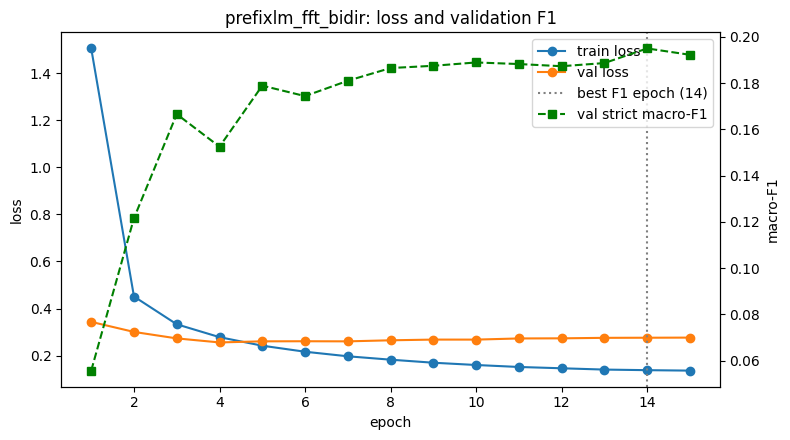

In [43]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train"]) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(epochs, history["train"], marker="o", label="train loss")
ax1.plot(epochs, history["val"], marker="o", label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")

ax2 = ax1.twinx()
ax2.plot(epochs, history["f1"], marker="s", color="green", linestyle="--", label="val strict macro-F1")
ax2.set_ylabel("macro-F1")

best = max(range(len(history["f1"])), key=lambda i: history["f1"][i]) + 1
ax1.axvline(best, color="gray", linestyle=":", label=f"best F1 epoch ({best})")

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title(f"{EXPERIMENT_NAME}: loss and validation F1")
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=150)
plt.show()

## 14. Save Final Model to Kaggle Output

In [44]:
size_kb = os.path.getsize(MODEL_PATH) / 1024
print(f"Model file size: {size_kb:.0f} KB")

run_info = {
    "experiment": EXPERIMENT_NAME,
    "window": WINDOW_SIZE, "stride": WINDOW_STRIDE,
    "epochs_run": len(history["f1"]), "best_val_f1": max(history["f1"]),
    "trainable_params": sum(p.numel() for p in ner_model.parameters() if p.requires_grad),
}
with open(os.path.join(OUTPUT_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
print(run_info)

Model file size: 446017 KB
{'experiment': 'prefixlm_fft_bidir', 'window': 1024, 'stride': 512, 'epochs_run': 15, 'best_val_f1': 0.19498978879435502, 'trainable_params': 101578777}


## For reload purpose

In [45]:
# # rebuild exactly as in training, then load the saved adapter + head
# lm = PrefixLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
#                            n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD)
# lm.load_state_dict(load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors")))
# ner_model = NERModel(lm, n_tags=len(TAGS))
# for p in ner_model.lm.parameters(): p.requires_grad = False
# ner_model.lm = inject_adapter_in_model(lora_cfg, ner_model.lm)   # same LoraConfig as training
# ner_model.to(device)
# print(ner_model.load_state_dict(torch.load(ADAPTER_PATH, map_location=device), strict=False).unexpected_keys)

## Predict fold3

In [46]:
test_pred = {}
for d in test_text:                       # fold3 documents, all required IDs
    test_pred[d] = [[int(s), int(e), lab] for s, e, lab in predict_spans(ner_model, d)]

assert set(test_pred) == set(test_text), "missing or extra document ids"
print("docs:", len(test_pred), "| total spans:", sum(len(v) for v in test_pred.values()))

# sanity: spans are inside the text, non-empty, labels valid
for d, spans in test_pred.items():
    n = len(test_text[d])
    for s, e, lab in spans:
        assert 0 <= s < e <= n and lab in LABELS, (d, s, e, lab)
print("format checks OK")
d0 = next(iter(test_pred))
print([(s, e, lab, test_text[d0][s:e]) for s, e, lab in test_pred[d0][:5]])

docs: 35 | total spans: 4878
format checks OK
[(18, 40, 'COURT', 'SUPREME COURT OF INDIA'), (70, 98, 'CASENO', 'CIVIL APPEAL NO.6580 OF 2008'), (100, 103, 'APP', 'RIS'), (163, 183, 'RESP', 'ESSCO FABS PVT. LTD.'), (213, 229, 'RESP', 'STATE OF HARYANA')]


## 21. Save prediction.json and Create CodaBench Submission ZIP

In [47]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_pred, f, ensure_ascii=False)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")     # must sit at the zip root

print("saved:", SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    print(z.namelist())                                    # expect ['prediction.json']

saved: /kaggle/working/cs781_phase2/prefixlm_fft_bidir/submission.zip
['prediction.json']


In [49]:
import shutil
shutil.make_archive("/kaggle/working/phase2_backup", "zip", "/kaggle/working/cs781_phase2")
shutil.copy("/kaggle/working/a1_tokenizer.py", "/kaggle/working/cs781_phase2/a1_tokenizer.py")
print(os.path.getsize("/kaggle/working/phase2_backup.zip") / 1e6, "MB")

377.756344 MB
